In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import joblib
from sklearn.metrics import mean_absolute_error, r2_score

# Conectar con la carpeta src para heredar nuestras clases
sys.path.append(os.path.abspath('..'))
from src.transformadores import LimpiadorFormatosKaggle, CalculadorDistancia

In [3]:
print("=====================================================================")
print(" 1. CARGA Y PREPARACIÓN DEL CONJUNTO DE PRUEBA (TEST SET)")
print("=====================================================================\n")

test_path = os.path.join('..', 'data', 'processed', 'test_processed.csv')
df_test = pd.read_csv(test_path)

# 1. Instanciamos los transformadores de Feature Engineering
limpiador = LimpiadorFormatosKaggle()
calculador = CalculadorDistancia()

# 2. Aplicamos las reglas de negocio (Regex y Haversine) a los datos crudos
df_test_final = calculador.transform(limpiador.transform(df_test))

# 3. Separar X (predictoras) e Y (objetivo) para la evaluación
X_test = df_test_final.drop(columns=['Time_taken(min)'])
y_test = df_test_final['Time_taken(min)'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

print(f"✓ Datos de prueba listos. Total de pedidos a evaluar en tiempo real: {X_test.shape[0]}")

 1. CARGA Y PREPARACIÓN DEL CONJUNTO DE PRUEBA (TEST SET)

✓ Datos de prueba listos. Total de pedidos a evaluar en tiempo real: 9119


In [5]:
print("=====================================================================")
print(" 2. CARGA DINÁMICA DE MODELOS MLOPS DESDE DISCO")
print("=====================================================================\n")

ruta_lr = os.path.join('..', 'models', 'modelo_regresion_lineal.joblib')
ruta_arbol = os.path.join('..', 'models', 'modelo_arbol_decision.joblib')
ruta_rf = os.path.join('..', 'models', 'modelo_random_forest.joblib')

modelo_lr = joblib.load(ruta_lr)
modelo_arbol = joblib.load(ruta_arbol)
modelo_rf = joblib.load(ruta_rf)

print("✓ Pipeline de Regresión Lineal cargado en RAM.")
print("✓ Pipeline de Árbol de Decisión cargado en RAM.")
print("✓ Pipeline de Random Forest cargado en RAM.")

 2. CARGA DINÁMICA DE MODELOS MLOPS DESDE DISCO

✓ Pipeline de Regresión Lineal cargado en RAM.
✓ Pipeline de Árbol de Decisión cargado en RAM.
✓ Pipeline de Random Forest cargado en RAM.


In [6]:
print("=====================================================================")
print(" 3. INFERENCIA Y CÁLCULO DE MÉTRICAS EN TIEMPO REAL")
print("=====================================================================\n")

modelos_dict = {
    'Regresión Lineal': modelo_lr,
    'Árbol de Decisión': modelo_arbol,
    'Random Forest': modelo_rf
}

resultados = []
mae_valores = []
r2_valores = []

for nombre, modelo in modelos_dict.items():
    # Ejecutar predicción en tiempo real usando el archivo .joblib
    y_pred = modelo.predict(X_test)
    
    # Calcular métricas dinámicamente
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred) * 100
    
    mae_valores.append(mae)
    r2_valores.append(r2)
    
    resultados.append({
        'Modelo Evaluado': nombre,
        'Varianza Explicada (R2)': f"{r2:.2f} %",
        'Error Absoluto Medio (MAE)': f"{mae:.2f} min"
    })

df_reporte = pd.DataFrame(resultados)
df_reporte.set_index('Modelo Evaluado', inplace=True)

print("--- REPORTE EJECUTIVO GENERADO DINÁMICAMENTE ---")
display(df_reporte)

 3. INFERENCIA Y CÁLCULO DE MÉTRICAS EN TIEMPO REAL

--- REPORTE EJECUTIVO GENERADO DINÁMICAMENTE ---


,Varianza Explicada (R2),Error Absoluto Medio (MAE)
Modelo Evaluado,,
Regresión Lineal,55.18 %,4.94 min
Árbol de Decisión,79.45 %,3.34 min
Random Forest,81.80 %,3.17 min


 4. DIAGNÓSTICO VISUAL COMPARATIVO



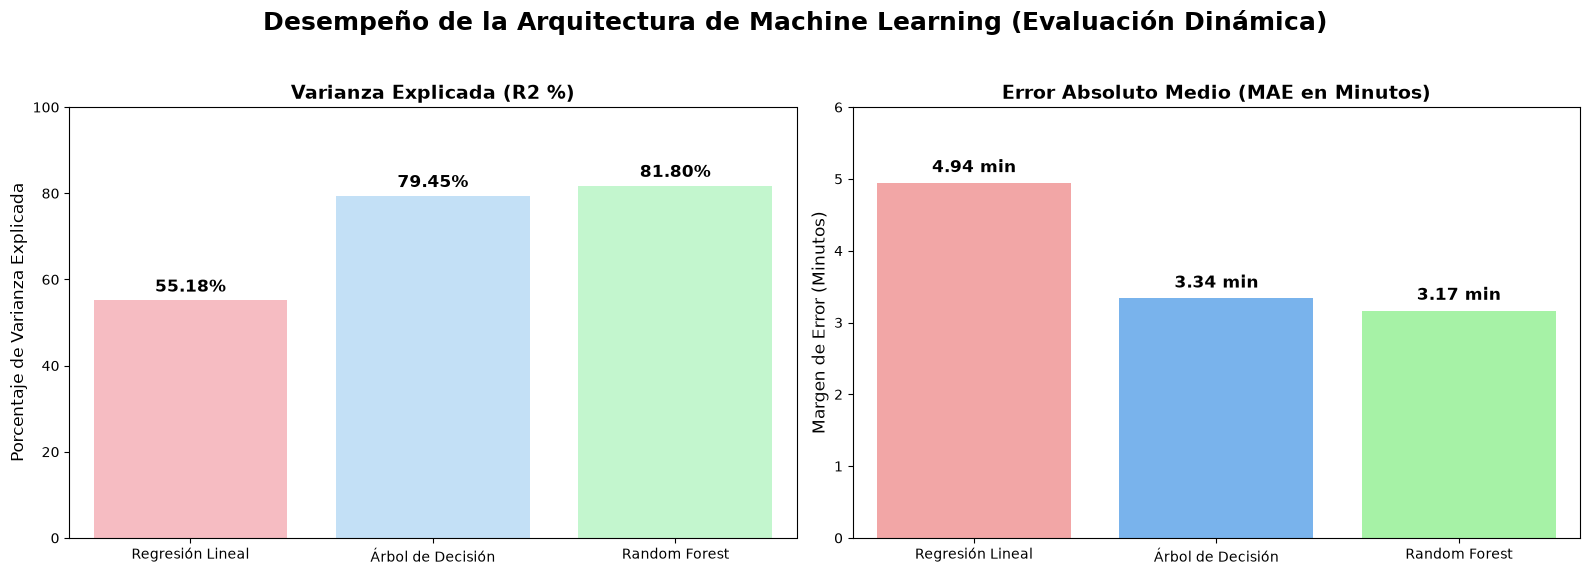

In [7]:
print("=====================================================================")
print(" 4. DIAGNÓSTICO VISUAL COMPARATIVO")
print("=====================================================================\n")

modelos_nombres = list(modelos_dict.keys())

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Desempeño de la Arquitectura de Machine Learning (Evaluación Dinámica)', fontsize=18, fontweight='bold')

# Gráfico 1: Varianza Explicada (R2)
grafico_r2 = sns.barplot(x=modelos_nombres, y=r2_valores, palette=['#ffb3ba', '#bae1ff', '#baffc9'], ax=ax[0], hue=modelos_nombres, legend=False)
ax[0].set_title('Varianza Explicada (R2 %)', fontsize=14, fontweight='bold')
ax[0].set_ylabel('Porcentaje de Varianza Explicada', fontsize=12)
ax[0].set_ylim(0, 100)

for i, v in enumerate(r2_valores):
    ax[0].text(i, v + 2, f"{v:.2f}%", ha='center', fontsize=12, fontweight='bold')

# Gráfico 2: Error Absoluto Medio (MAE)
grafico_mae = sns.barplot(x=modelos_nombres, y=mae_valores, palette=['#ff9999', '#66b3ff', '#99ff99'], ax=ax[1], hue=modelos_nombres, legend=False)
ax[1].set_title('Error Absoluto Medio (MAE en Minutos)', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Margen de Error (Minutos)', fontsize=12)
ax[1].set_ylim(0, 6)

for i, v in enumerate(mae_valores):
    ax[1].text(i, v + 0.15, f"{v:.2f} min", ha='center', fontsize=12, fontweight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()